<a href="https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-II/blob/main/notebooks/05_mnist_mlp_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 05 — Clasificación multiclase MNIST con PyTorch (MLP, sin CNN)

**Curso:** Deep Learning – Conceptos · Especialización en Inteligencia Artificial · Universidad de Cundinamarca
**Semanas 3 y 4:** la misma arquitectura del Notebook 04, ahora con PyTorch y un ciclo de entrenamiento explícito.

Para que la comparación con Keras sea justa se replican todas las decisiones de diseño:

| Aspecto | Keras (Notebook 04) | PyTorch (este notebook) |
|---|---|---|
| Arquitectura | 784 → 256 → 128 → 10 | `nn.Flatten` + `nn.Linear` 784 → 256 → 128 → 10 |
| Inicialización | Glorot uniforme, sesgos 0 | `xavier_uniform_`, sesgos 0 |
| Optimizador | Adam, lr = 1e-3, ε = 1e-7 | `optim.Adam`, lr = 1e-3, eps = 1e-7 |
| Pérdida | `sparse_categorical_crossentropy` | `nn.CrossEntropyLoss` (Softmax + NLL) |
| Lote / épocas | 128 / 15 | 128 / 15 |
| Validación | últimas 6 000 imágenes | últimas 6 000 imágenes |

**Restricción:** no se usa `nn.Conv2d`; todas las capas son lineales (densas).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-II/blob/main/notebooks/05_mnist_mlp_pytorch.ipynb)

In [1]:
# ============================================================
# 0. Importaciones, dispositivo y semillas
# ============================================================
import os
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
FIG_DIR = "figuras"
os.makedirs(FIG_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| dispositivo:", device)

PyTorch: 2.11.0+cu130 | dispositivo: cuda


## 1. Carga y preprocesamiento

`torchvision.datasets.MNIST` descarga los archivos originales. Las imágenes se convierten **una sola vez** a un
tensor `float32` en $[0,1]$ (equivalente a `transforms.ToTensor()`, pero sin repetir la conversión en cada
época, lo que acelera mucho el entrenamiento). Las etiquetas quedan como enteros `int64`, que es el formato que
espera `nn.CrossEntropyLoss`.

In [2]:
# ============================================================
# 1. Descarga, normalización, partición y DataLoaders
# ============================================================
train_raw = datasets.MNIST(root="data", train=True, download=True)
test_raw = datasets.MNIST(root="data", train=False, download=True)

# uint8 [0, 255] (N, 28, 28) -> float32 [0, 1] (N, 1, 28, 28)
x_train_all = train_raw.data.float().div(255.0).unsqueeze(1)
y_train_all = train_raw.targets.long()
x_test = test_raw.data.float().div(255.0).unsqueeze(1)
y_test = test_raw.targets.long()
print("Train:", tuple(x_train_all.shape), "| Test:", tuple(x_test.shape))
print(f"Rango de píxeles: {x_train_all.min():.1f} - {x_train_all.max():.1f}")
print("Aplanado (ilustrativo):", tuple(x_train_all.shape), "->", tuple(x_train_all.flatten(1).shape))

# Mismo esquema que validation_split=0.1 de Keras: las últimas 6 000 imágenes para validación
n_val = 6000
train_ds = TensorDataset(x_train_all[:-n_val], y_train_all[:-n_val])
val_ds = TensorDataset(x_train_all[-n_val:], y_train_all[-n_val:])
test_ds = TensorDataset(x_test, y_test)

BATCH_SIZE = 128
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader = DataLoader(val_ds, batch_size=1024)
test_loader = DataLoader(test_ds, batch_size=1024)
print(f"Lotes por época: {len(train_loader)} | muestras train/val/test: "
      f"{len(train_ds)}/{len(val_ds)}/{len(test_ds)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 458kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.43MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.6MB/s]


Train: (60000, 1, 28, 28) | Test: (10000, 1, 28, 28)
Rango de píxeles: 0.0 - 1.0
Aplanado (ilustrativo): (60000, 1, 28, 28) -> (60000, 784)
Lotes por época: 422 | muestras train/val/test: 54000/6000/10000


## 2. Arquitectura: clase que hereda de `nn.Module`

La capa de salida devuelve **logits** (sin Softmax) porque `nn.CrossEntropyLoss` aplica internamente
`log_softmax` + `NLLLoss`, que es numéricamente más estable. Para obtener probabilidades se aplica
`torch.softmax` al predecir.

In [3]:
class MLPMnist(nn.Module):
    def __init__(self, n_entrada=784, ocultas=(256, 128), n_clases=10):
        super().__init__()
        self.aplanado = nn.Flatten()                      # (N, 1, 28, 28) -> (N, 784)
        self.red = nn.Sequential(
            nn.Linear(n_entrada, ocultas[0]), nn.ReLU(),
            nn.Linear(ocultas[0], ocultas[1]), nn.ReLU(),
            nn.Linear(ocultas[1], n_clases),              # logits
        )
        self._inicializar()

    def _inicializar(self):
        # Misma inicialización que Keras Dense por defecto (Glorot uniforme, sesgos en cero)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.red(self.aplanado(x))


modelo = MLPMnist().to(device)
print(modelo)
n_param = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(f"Parámetros entrenables: {n_param:,}")

MLPMnist(
  (aplanado): Flatten(start_dim=1, end_dim=-1)
  (red): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parámetros entrenables: 235,146


## 3. Función de pérdida y optimizador

In [4]:
criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr=1e-3, eps=1e-7)

## 4. Ciclo de entrenamiento y validación explícito

Por cada lote: `zero_grad()` → **forward** → pérdida → `backward()` (backpropagation con *autograd*) →
`optimizer.step()` (actualización de pesos). La validación usa `model.eval()` y `torch.no_grad()` para no
construir el grafo de gradientes.

In [5]:
def evaluar(modelo, loader):
    modelo.eval()
    perdida_total, correctos, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = modelo(xb)
            perdida_total += criterio(logits, yb).item() * len(yb)
            correctos += (logits.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return perdida_total / n, correctos / n


EPOCHS = 15
historial = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
tiempos = []

for epoch in range(1, EPOCHS + 1):
    t0 = time.perf_counter()
    modelo.train()
    perdida_acum, correctos, n = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizador.zero_grad()            # 1) reinicia los gradientes acumulados
        logits = modelo(xb)                # 2) forward pass
        perdida = criterio(logits, yb)     # 3) cálculo de la pérdida
        perdida.backward()                 # 4) backpropagation (autograd)
        optimizador.step()                 # 5) actualización de parámetros (Adam)
        perdida_acum += perdida.item() * len(yb)
        correctos += (logits.argmax(dim=1) == yb).sum().item()
        n += len(yb)
    val_loss, val_acc = evaluar(modelo, val_loader)
    tiempos.append(time.perf_counter() - t0)

    historial["loss"].append(perdida_acum / n); historial["accuracy"].append(correctos / n)
    historial["val_loss"].append(val_loss); historial["val_accuracy"].append(val_acc)
    print(f"Época {epoch:2d}/{EPOCHS} - {tiempos[-1]:.1f}s - loss: {historial['loss'][-1]:.4f} - "
          f"accuracy: {historial['accuracy'][-1]:.4f} - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

print(f"\nTiempo medio por época: {np.mean(tiempos):.2f} s")

Época  1/15 - 2.1s - loss: 0.2937 - accuracy: 0.9159 - val_loss: 0.1138 - val_accuracy: 0.9685
Época  2/15 - 1.5s - loss: 0.1106 - accuracy: 0.9665 - val_loss: 0.0961 - val_accuracy: 0.9722
Época  3/15 - 1.3s - loss: 0.0711 - accuracy: 0.9784 - val_loss: 0.0805 - val_accuracy: 0.9757
Época  4/15 - 1.2s - loss: 0.0505 - accuracy: 0.9845 - val_loss: 0.0765 - val_accuracy: 0.9770
Época  5/15 - 1.3s - loss: 0.0373 - accuracy: 0.9879 - val_loss: 0.0717 - val_accuracy: 0.9802
Época  6/15 - 1.3s - loss: 0.0276 - accuracy: 0.9911 - val_loss: 0.0859 - val_accuracy: 0.9777
Época  7/15 - 1.3s - loss: 0.0226 - accuracy: 0.9933 - val_loss: 0.0764 - val_accuracy: 0.9798
Época  8/15 - 1.4s - loss: 0.0192 - accuracy: 0.9939 - val_loss: 0.0880 - val_accuracy: 0.9775
Época  9/15 - 1.6s - loss: 0.0164 - accuracy: 0.9947 - val_loss: 0.0852 - val_accuracy: 0.9808
Época 10/15 - 1.3s - loss: 0.0140 - accuracy: 0.9952 - val_loss: 0.0844 - val_accuracy: 0.9803
Época 11/15 - 1.3s - loss: 0.0104 - accuracy: 0.99

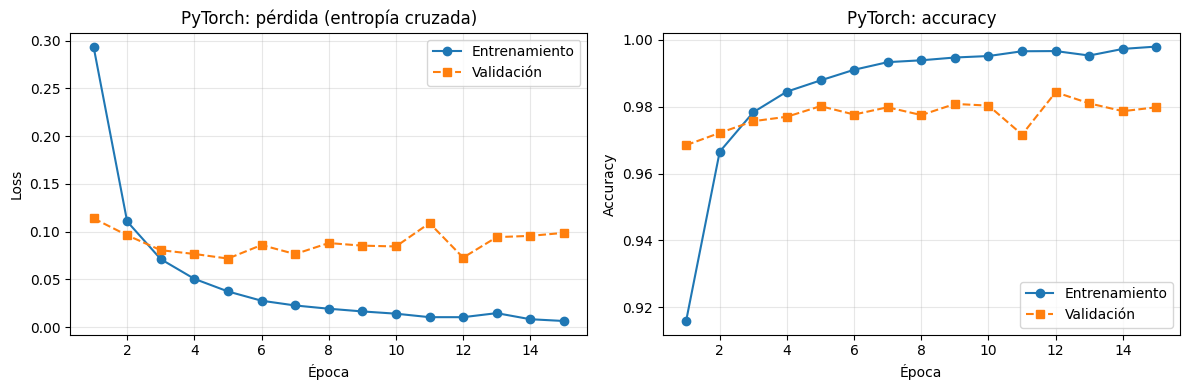

In [6]:
ep = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, historial["loss"], "o-", label="Entrenamiento"); axes[0].plot(ep, historial["val_loss"], "s--", label="Validación")
axes[0].set_title("PyTorch: pérdida (entropía cruzada)"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("Loss")
axes[1].plot(ep, historial["accuracy"], "o-", label="Entrenamiento"); axes[1].plot(ep, historial["val_accuracy"], "s--", label="Validación")
axes[1].set_title("PyTorch: accuracy"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_pytorch_curvas.png", dpi=150); plt.show()

## 5. Métricas finales en el conjunto de prueba

PyTorch -> test loss: 0.0935 | test accuracy: 0.9800

Reporte de clasificación por dígito:

              precision    recall  f1-score   support

           0     0.9908    0.9908    0.9908       980
           1     0.9947    0.9877    0.9912      1135
           2     0.9798    0.9884    0.9841      1032
           3     0.9660    0.9842    0.9750      1010
           4     0.9709    0.9847    0.9778       982
           5     0.9850    0.9596    0.9722       892
           6     0.9791    0.9791    0.9791       958
           7     0.9842    0.9708    0.9775      1028
           8     0.9772    0.9702    0.9737       974
           9     0.9715    0.9812    0.9763      1009

    accuracy                         0.9800     10000
   macro avg     0.9799    0.9797    0.9798     10000
weighted avg     0.9801    0.9800    0.9800     10000



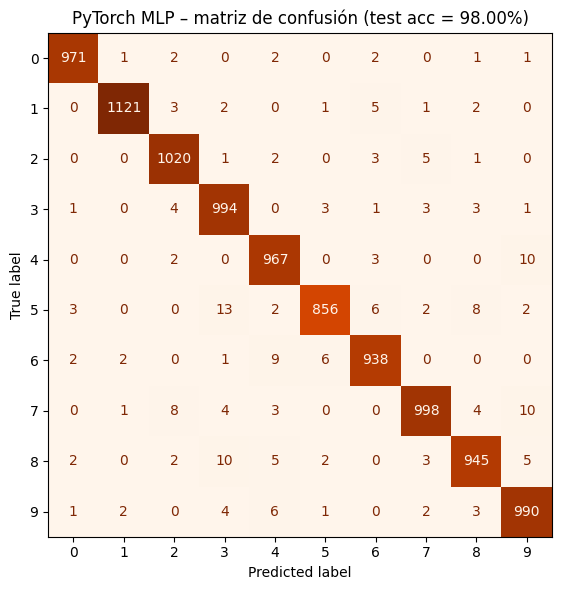

Confusiones más frecuentes (real -> predicho: casos):
  5 -> 3: 13
  7 -> 9: 10
  4 -> 9: 10
  8 -> 3: 10
  6 -> 4: 9


In [7]:
test_loss, test_acc = evaluar(modelo, test_loader)
print(f"PyTorch -> test loss: {test_loss:.4f} | test accuracy: {test_acc:.4f}")

modelo.eval()
with torch.no_grad():
    logits_test = torch.cat([modelo(xb.to(device)).cpu() for xb, _ in test_loader])
probs = torch.softmax(logits_test, dim=1).numpy()
y_pred = probs.argmax(axis=1)
y_true = y_test.numpy()

print("\nReporte de clasificación por dígito:\n")
print(classification_report(y_true, y_pred, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Oranges", colorbar=False, values_format="d")
ax.set_title(f"PyTorch MLP – matriz de confusión (test acc = {test_acc:.2%})")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_pytorch_matriz_confusion.png", dpi=150); plt.show()

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
top = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:5], cm.shape))[0]
print("Confusiones más frecuentes (real -> predicho: casos):")
for r, p in top:
    print(f"  {r} -> {p}: {cm[r, p]}")

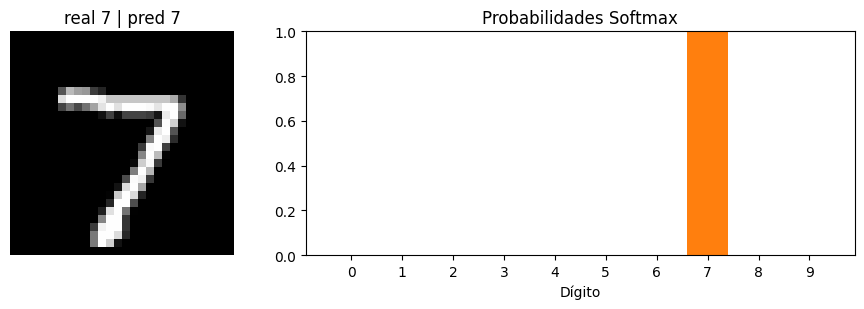

In [8]:
# Predicción individual: se toma una imagen de prueba y se muestran las 10 probabilidades Softmax
idx = 0
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [1, 2]})
axes[0].imshow(x_test[idx, 0], cmap="gray"); axes[0].axis("off")
axes[0].set_title(f"real {y_true[idx]} | pred {y_pred[idx]}")
axes[1].bar(range(10), probs[idx], color="tab:orange"); axes[1].set_xticks(range(10))
axes[1].set_title("Probabilidades Softmax"); axes[1].set_xlabel("Dígito"); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_pytorch_prediccion_individual.png", dpi=150); plt.show()

In [9]:
# ============================================================
# 6. Guardado de métricas para la tabla comparativa
# ============================================================
metricas = {
    "framework": "PyTorch",
    "version": torch.__version__,
    "parametros": int(n_param),
    "test_accuracy": float(test_acc),
    "test_loss": float(test_loss),
    "train_loss_final": float(historial["loss"][-1]),
    "val_loss_final": float(historial["val_loss"][-1]),
    "val_accuracy_final": float(historial["val_accuracy"][-1]),
    "segundos_por_epoca": float(np.mean(tiempos)),
    "segundos_por_epoca_sin_primera": float(np.mean(tiempos[1:])),
    "historial": historial,
    "matriz_confusion": cm.tolist(),
    "reporte": classification_report(y_true, y_pred, digits=4, output_dict=True),
}
with open("metricas_pytorch.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, indent=2)
print("Métricas guardadas en metricas_pytorch.json")

Métricas guardadas en metricas_pytorch.json


In [10]:
!zip -r resultados.zip figuras metricas_*.json
from google.colab import files
files.download("resultados.zip")

  adding: figuras/ (stored 0%)
  adding: figuras/05_pytorch_curvas.png (deflated 9%)
  adding: figuras/05_pytorch_matriz_confusion.png (deflated 14%)
  adding: figuras/05_pytorch_prediccion_individual.png (deflated 23%)
  adding: metricas_pytorch.json (deflated 73%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>